# 项目二 · 电商客户流失分析 —— 数据分析与建模 Notebook

> 依照《数据分析实务实训》项目一「心脏病发病预测」实训报告书的流程完成：
> **探查清洗 → EDA 可视化 → 算法模型对比 → 调优 → 评估选型 → 可解释 → 预测输出**

**数据集划分**：
- **训练集** `rawData.csv`：40450 行 19 字段，R 列（第 18 列）`Churned` 为目标变量，1=流失、0=留存（流失率约 28.9%）。字段含义见 `数据字典.docx`。
- **验证集** `测试集.csv`：5000 行 18 字段，不含目标列，用于最终预测。

**最终成果**：对**验证集全部 5000 行**预测，生成 `prediction_result.csv` —— 仅两列：`行号`（验证集中的原始行号 0~4999，便于核对）、`预测是否流失`（0/1）。完整可复跑代码见本 Notebook 第 5 章「预测与结果输出」。

**代码注释说明**：每段代码的中文注释解释「在做什么、为什么这么做」，便于理解后独立复述。

---
## 0. 环境准备与全局设置

导入后续需要的库，并统一做三件事：
1. 设置随机种子 → 保证数据集划分、模型训练结果**可复现**；
2. 设置中文字体 → matplotlib 中文标题/坐标轴正常显示；
3. 创建图片目录 → 统一存放 EDA 与评估图表。

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, auc, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')          # 忽略无害警告，输出更干净
RANDOM_SEED = 42                           # 固定随机种子，保证结果可复现
np.random.seed(RANDOM_SEED)
sns.set_theme(style='whitegrid', palette='Set2')  # 先设主题，避免其重置字体配置
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']  # Windows 中文字体
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.unicode_minus'] = False

# 工作目录为当前 notebook 所在目录（Jupyter 打开 notebook 时自动切换到该文件所在目录）
BASE_DIR = os.getcwd()
FIG_DIR = os.path.join(BASE_DIR, 'img')
os.makedirs(FIG_DIR, exist_ok=True)
TARGET = 'Churned'
CAT_COLS = ['Gender', 'Country', 'City', 'Signup_Quarter']
NUM_COLS = ['Age','Session_Duration_Avg','Pages_Per_Session','Total_Purchases',
            'Average_Order_Value','Days_Since_Last_Purchase','Discount_Usage_Rate',
            'Returns_Rate','Email_Open_Rate','Customer_Service_Calls',
            'Product_Reviews_Written','Payment_Method_Diversity','Lifetime_Value','Credit_Balance']

# 字段中文名：来自《数据字典.docx》，只用于绘图显示，不改动建模用的原始列名
FIELD_CN = {
    'Age': '用户年龄', 'Gender': '性别', 'Country': '国家', 'City': '城市',
    'Signup_Quarter': '注册季度', 'Session_Duration_Avg': '平均会话时长',
    'Pages_Per_Session': '每次会话浏览页面数', 'Total_Purchases': '总购买次数',
    'Average_Order_Value': '平均订单价值', 'Days_Since_Last_Purchase': '距上次购买天数',
    'Lifetime_Value': '生命周期总价值', 'Credit_Balance': '账户余额',
    'Email_Open_Rate': '邮件打开率', 'Customer_Service_Calls': '客服通话次数',
    'Product_Reviews_Written': '产品评论数', 'Discount_Usage_Rate': '折扣使用率',
    'Returns_Rate': '退货率', 'Payment_Method_Diversity': '支付方式多样性',
    'Churned': '目标标签',
}
# 类别取值中文名：字典给出英文取值，这里补上中文显示
VALUE_CN = {
    'Female': '女', 'Male': '男', 'Other': '其他',
    'USA': '美国', 'UK': '英国', 'Canada': '加拿大', 'Germany': '德国',
    'Australia': '澳大利亚', 'France': '法国', 'India': '印度', 'Japan': '日本',
    'NewYork': '纽约', 'New York': '纽约', 'London': '伦敦', 'Delhi': '德里',
    'Houston': '休斯敦', 'Phoenix': '菲尼克斯', 'Chicago': '芝加哥',
    'Los Angeles': '洛杉矶', 'Manchester': '曼彻斯特',
    'Nagoya': '名古屋', 'Tokyo': '东京', 'Nice': '尼斯', 'Frankfurt': '法兰克福',
    'Adelaide': '阿德莱德', 'Toronto': '多伦多', 'Melbourne': '墨尔本',
    'Brisbane': '布里斯班', 'Perth': '珀斯', 'Kyoto': '京都', 'Ottawa': '渥太华',
    'Bangalore': '班加罗尔', 'Berlin': '柏林', 'Birmingham': '伯明翰',
    'Calgary': '卡尔加里', 'Chennai': '金奈', 'Cologne': '科隆',
    'Glasgow': '格拉斯哥', 'Hamburg': '汉堡', 'Hyderabad': '海得拉巴',
    'Leeds': '利兹', 'Lyon': '里昂', 'Marseille': '马赛', 'Montreal': '蒙特利尔',
    'Mumbai': '孟买', 'Munich': '慕尼黑', 'Osaka': '大阪', 'Paris': '巴黎',
    'Sydney': '悉尼', 'Toulouse': '图卢兹', 'Vancouver': '温哥华', 'Yokohama': '横滨',
    'Q1': '第一季度', 'Q2': '第二季度', 'Q3': '第三季度', 'Q4': '第四季度',
    '0': '留存', '1': '流失',
}

def cn_label(col):
    """把字段名/独热列名转成中文，如 Gender_Male -> 性别_男、Signup_Quarter_Q3 -> 注册季度_第三季度。"""
    name = str(col)
    if name in FIELD_CN:
        return FIELD_CN[name]
    for prefix in sorted(FIELD_CN, key=len, reverse=True):
        if name.startswith(prefix + '_'):
            suffix = name[len(prefix) + 1:]
            for key in (suffix, suffix.title(), suffix.upper(), suffix.lower()):
                if key in VALUE_CN:
                    return '%s_%s' % (FIELD_CN[prefix], VALUE_CN[key])
            return '%s_%s' % (FIELD_CN[prefix], suffix)
    for key in (name, name.title(), name.upper(), name.lower()):
        if key in VALUE_CN:
            return VALUE_CN[key]
    return name



---
## 1. 数据探查与清洗

**为什么做**：脏数据（缺失、重复、错误格式、超出范围的值）会干扰分析，必须先处理。
**如何做**：查缺失/重复/异常；带单位的字符串提取数字；类别写法统一；超范围值按缺失用中位数填充。
**注意**：清洗阶段不删行；去重只在建模评估阶段进行（避免同一条样本同时进入训练与测试集导致评估虚高）。
验证集同样按此规则清洗，再对全部 5000 行预测。

### 1.1 读取数据与整体概览

In [2]:
df = pd.read_csv('data/rawData.csv')
print('数据规模：', df.shape, '（行数 × 列数）')
print('目标列位置：第', df.columns.get_loc(TARGET)+1, '列（Excel 列 R）')
print('\n字段与数据类型：'); print(df.dtypes.to_string())
print('\n前 5 行：'); display(df.head())

数据规模： (40450, 19) （行数 × 列数）
目标列位置：第 18 列（Excel 列 R）

字段与数据类型：
Age                         float64
Gender                       object
Country                      object
City                         object
Session_Duration_Avg        float64
Pages_Per_Session           float64
Total_Purchases              object
Average_Order_Value          object
Days_Since_Last_Purchase    float64
Discount_Usage_Rate         float64
Returns_Rate                float64
Email_Open_Rate             float64
Customer_Service_Calls      float64
Product_Reviews_Written     float64
Payment_Method_Diversity    float64
Lifetime_Value              float64
Credit_Balance              float64
Churned                       int64
Signup_Quarter               object

前 5 行：


,Age,Gender,Country,City,Session_Duration_Avg,Pages_Per_Session,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,37.0,Female,USA,Houston,32.5,7.0,7.800000000000001,153.15,22.0,0.00,6.3,0.0,5.0,4.0,1.0,905.35,2980.0,0,Q4
1,49.0,Male,USA,New York,23.5,4.6,13.0,81.91,14.0,65.52,12.9,8.8,9.0,0.0,1.0,947.44,1534.0,0,Q4
2,40.0,Female,USA,Houston,0.0,6.8,3.0,124.7,48.0,16.80,16.7,14.7,8.0,0.0,5.0,354.49,894.0,1,Q1
3,43.0,Male,USA,Chicago,36.3,5.7,10.0,112.1,11.0,32.00,2.4,0.0,5.0,3.0,3.0,1258.89,2134.0,0,Q3
4,33.0,Female,Canada,Montreal,33.6,0.0,15.0,149.68,86.0,27.00,2.5,0.0,6.0,5.0,3.0,1980.81,2491.0,1,Q3


**怎么读这段输出**：`shape` 告诉我们数据有 40450 行、19 个字段。
这 19 列可归为三类：① 4 个类别字段（`Gender`/`Country`/`City`/`Signup_Quarter`）；
② 14 个数值型行为与价值字段（年龄、会话时长、购买次数、消费金额、各类比率等）；
③ 第 19 列 `Churned` 目标变量。`dtypes` 输出里如果某列显示为 `object`，
说明它被读成了字符串——后面的异常值检查会告诉我们，其中藏着带单位的脏数据。
`head()` 让我们直观看到每行是一条客户记录，一行代表一个样本。

### 1.2 缺失值 / 重复值 / 目标分布检查

In [3]:
print('各字段缺失值数量：')
print(df.isnull().sum()[df.isnull().sum()>0].to_string())
print('\n完全重复的行数：', df.duplicated().sum())
print('\n目标变量分布：'); print(df[TARGET].value_counts().to_string())
print('流失率：%.2f%%' % (df[TARGET].mean()*100))

各字段缺失值数量：
Session_Duration_Avg    2024
Email_Open_Rate         3224
Credit_Balance          1215

完全重复的行数： 244

目标变量分布：
0    28749
1    11701
流失率：28.93%


**为什么要查这三件事**：
- **缺失值**：模型无法直接处理空值，必须决定填充还是删除；
- **重复行**：完全相同的两条记录若一条进训练集、一条进测试集，等于「考试题泄题」，评估会虚高，所以建模前要去重；
- **目标分布**：决定评估指标的选择。这里流失约 28.9%、留存约 71.1%，属于中度类别不平衡。
  注意一个陷阱：如果模型「全部预测为留存」，准确率就有 71.1%，但这毫无价值——
  所以后面不能只看准确率，必须补充 AUC 和召回率。
本阶段只是**检查**，不删任何行，以保证清洗后仍能与原始 40450 行逐行对应。

### 1.3 异常值检查（关键）

数据字典指出 `Churned` 之外还有多处脏数据：
- `Total_Purchases` 出现 `'13.0次'`、`Average_Order_Value` 出现 `'$159.94'` → 数字被包进了字符串；
- `Gender` 出现字典外的 `'F'`、`'1'`；`Country` 出现大小写与空格变体（如 `'usa '`）；
- `Age` 最大 200（字典 0~65）、会话时长/折扣率/邮件打开率/退货率出现负数或 >100 的值。

In [4]:
print('Total_Purchases 非纯数字示例：',
      df.loc[~df['Total_Purchases'].astype(str).str.fullmatch(r'[\d.]+'), 'Total_Purchases'].head(5).tolist())
print('Average_Order_Value 非纯数字示例：',
      df.loc[~df['Average_Order_Value'].astype(str).str.fullmatch(r'[\d.]+'), 'Average_Order_Value'].head(5).tolist())
print('Gender 取值：', df['Gender'].value_counts().to_dict())
print('Country 取值：', df['Country'].value_counts().head(12).to_dict())
print('Age>65：', (df['Age']>65).sum(), '| Session<0：', (df['Session_Duration_Avg']<0).sum(),
      '| 折扣率越界：', ((df['Discount_Usage_Rate']<0)|(df['Discount_Usage_Rate']>100)).sum(),
      '| 邮件打开率>100：', (df['Email_Open_Rate']>100).sum(),
      '| 退货率>100：', (df['Returns_Rate']>100).sum())

Total_Purchases 非纯数字示例： ['16.0次', '18.2次', '19.5次', '15.6次', '19.0次']
Average_Order_Value 非纯数字示例： ['$200.16', '$102.89', '$82.16', '$149.95', '$90.74']
Gender 取值： {'Female': 19681, 'Male': 18836, 'F': 792, 'Other': 741, '1': 400}
Country 取值： {'USA': 13588, 'UK': 5901, 'Canada': 4699, 'Germany': 3822, 'Australia': 3230, 'France': 3135, 'India': 2723, 'Japan': 2006, 'usa': 437, 'uk': 163, 'canada': 160, 'france': 112}
Age>65： 369 | Session<0： 168 | 折扣率越界： 284 | 邮件打开率>100： 158 | 退货率>100： 200


**这些异常为什么要重视**：
`Total_Purchases` 和 `Average_Order_Value` 本应是数值，却被读成字符串（如 `13.0次`、`$159.94`）。
如果不处理就直接做独热编码，每一个不同的字符串都会被当成一个独立类别，
特征维度会从约 70 列暴增到上万列——模型又慢又容易过拟合，这正是本项目最关键的脏数据坑。
类别字段的脏写法同理：`F` 与 `Female`、`usa` 与 `USA` 会被当成不同类别，同一类被拆成多个哑变量。
越界值（`Age` 最大 200、比率超过 100）明显违反数据字典的物理含义，属于录入错误，也必须纠正。

### 1.4 执行清洗

In [5]:
data = df.copy()

# (1) 带单位的字符串 -> 数值（正则提取数字部分）
for col in ['Total_Purchases','Average_Order_Value']:
    data[col] = pd.to_numeric(data[col].astype(str).str.extract(r'([-+]?\d+\.?\d*)')[0], errors='coerce')

# (2) 类别写法统一
data['Gender'] = data['Gender'].astype(str).str.strip().replace({'F':'Female','1':'Male'})
canon_country = {'usa':'USA','uk':'UK','canada':'Canada','germany':'Germany',
                 'australia':'Australia','france':'France','india':'India','japan':'Japan'}
data['Country'] = data['Country'].astype(str).str.strip().str.lower().map(
    lambda x: canon_country.get(x, x.title()))
data['City'] = data['City'].astype(str).str.strip()
data['Signup_Quarter'] = data['Signup_Quarter'].astype(str).str.strip()

# (3) 违反字典范围的数值 -> NaN（视为缺失）
data.loc[(data['Age']<0)|(data['Age']>65), 'Age'] = np.nan
data.loc[data['Session_Duration_Avg']<0, 'Session_Duration_Avg'] = np.nan
for col in ['Discount_Usage_Rate','Email_Open_Rate','Returns_Rate']:
    data.loc[(data[col]<0)|(data[col]>100), col] = np.nan

# (4) 中位数填充（比均值稳健，不受极端值影响）
for col in NUM_COLS:
    if data[col].isna().sum() > 0:
        med = data[col].median()
        data[col] = data[col].fillna(med)
        print('%s: 填充 %d 个值, 中位数=%.2f' % (col, df[col].isna().sum() + 0, med))

print('清洗后缺失值总数：', data.isnull().sum().sum())

Age: 填充 0 个值, 中位数=36.00
Session_Duration_Avg: 填充 2024 个值, 中位数=25.70
Discount_Usage_Rate: 填充 0 个值, 中位数=37.80
Returns_Rate: 填充 0 个值, 中位数=4.90
Email_Open_Rate: 填充 3224 个值, 中位数=18.80
Credit_Balance: 填充 1215 个值, 中位数=1695.00
清洗后缺失值总数： 0


**清洗规则逐条解释**：
1. `copy()` 保留原始 `df` 不动，所有修改只作用于副本 `data`，便于前后对比。
2. 正则 `([-+]?\d+\.?\d*)` 从字符串中抠出数字部分：`13.0次` → 13.0，`$159.94` → 159.94；
   `errors='coerce'` 把实在提取不出的置为缺失值。
3. 类别归一：用映射表把 `F`→`Female`、`1`→`Male`；国家名先去空格、转小写再映射回标准写法。
4. 越界值处理分两步：先把违反字典范围的值置为 `NaN`（当作缺失），再统一填充。
5. 为什么用**中位数**而不是均值填充：中位数不受极端大值/小值拉扯，填充后更能代表典型客户；
   而且相比删除整行，填充能保住样本量。

清洗到这里，保证了两件事：
**每一列都是合法数值类型**（字符串数字已还原），**每个类别写法唯一**（不再有 F/Female 分裂）。
这是后续独热编码能得到合理特征维度的前提。注意清洗本身不追求「数据好看」，
而是防止脏数据把模型带偏。

**结果**：清洗后无缺失；数值列全部为合法类型，类别字段写法统一。共 40450 行保持不变，
为最终逐行输出预测保留了完整的行号对应关系。

---
## 2. EDA 可视化（探索性数据分析）

**为什么做**：找出哪些因素与流失相关，为建模与业务解释提供依据。
**如何做**：看目标分布是否不平衡；按流失/留存对比数值分布；算各类别的流失率；看相关性热力图；深挖重点特征。

### 2.1 目标变量分布

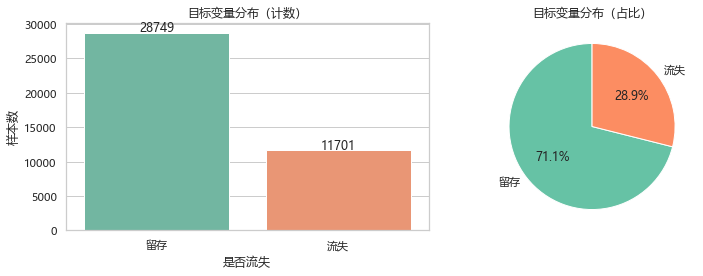

In [6]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
cnt = data[TARGET].map({0:'留存',1:'流失'}).value_counts()
sns.countplot(x=data[TARGET].map({0:'留存',1:'流失'}), ax=axes[0], order=['留存','流失'])
axes[0].set_title('目标变量分布（计数）'); axes[0].set_xlabel('是否流失'); axes[0].set_ylabel('样本数')
for i,v in enumerate(cnt): axes[0].text(i, v+100, str(v), ha='center')
axes[1].pie(cnt.values, labels=cnt.index, autopct='%1.1f%%', startangle=90)
axes[1].set_title('目标变量分布（占比）')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/01_目标分布.png', dpi=110); plt.show()
# 读图要点：流失约 28.9%，存在一定类别不平衡，评估不能只看准确率，要看 AUC/召回率。

**读图要点**：左图是计数、右图是占比，流失客户约占 28.9%。
这个比例直接决定了后面的评估策略——因为「全预测留存」就能拿到 71.1% 准确率，
所以必须引入对不平衡更稳健的 **AUC**，以及能反映「找出多少流失客户」的**召回率**。
如果课程或业务更看重「尽量找出潜在流失客户」，最终还可以在预测阶段下调分类阈值。

### 2.2 数值特征分布（按是否流失对比）

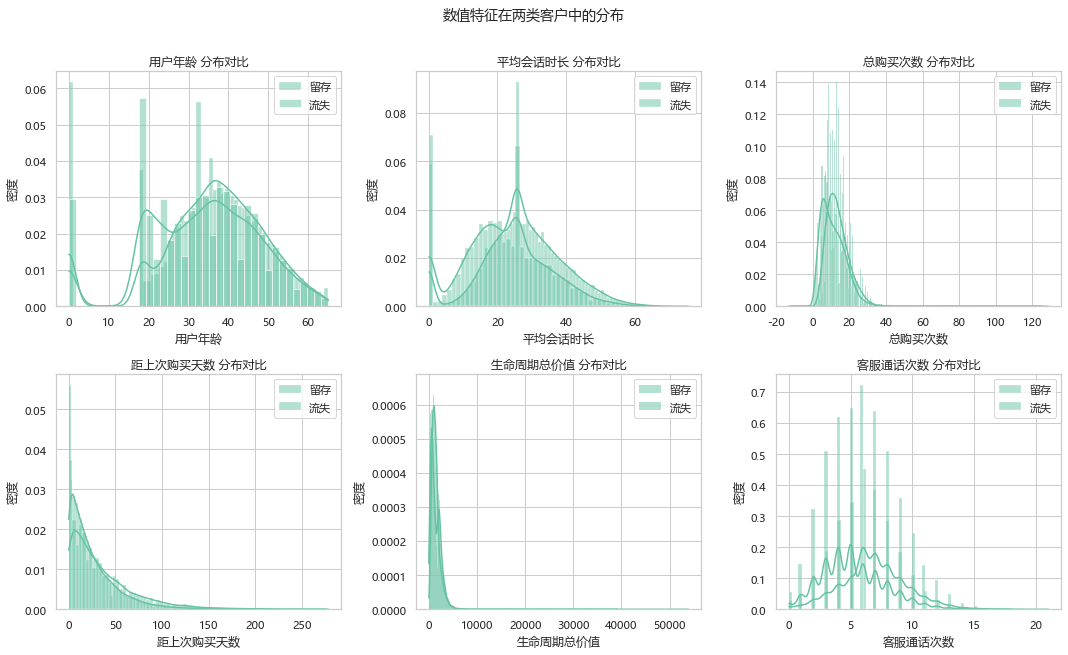

In [7]:
show_num = ['Age','Session_Duration_Avg','Total_Purchases',
            'Days_Since_Last_Purchase','Lifetime_Value','Customer_Service_Calls']
fig, axes = plt.subplots(2,3,figsize=(15,9))
for ax, col in zip(axes.flat, show_num):
    for label, name in [(0,'留存'),(1,'流失')]:
        sns.histplot(data[data[TARGET]==label][col], ax=ax, label=name, kde=True, stat='density', alpha=0.5)
    ax.set_title(f'{cn_label(col)} 分布对比'); ax.set_xlabel(cn_label(col)); ax.set_ylabel('密度'); ax.legend()
plt.suptitle('数值特征在两类客户中的分布', y=1.01, fontsize=14)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/02_数值特征分布.png', dpi=110, bbox_inches='tight'); plt.show()

**怎么看密度对比图**：每条曲线是核密度估计（KDE），反映该特征在两类客户中的分布形状。
两条曲线**重叠越多**，说明这个特征越难区分流失与留存；**错位越明显**，区分能力越强。
重点观察 `Days_Since_Last_Purchase`（距上次购买天数）和 `Customer_Service_Calls`（客服通话次数）
是否出现整体右移——错位越大的特征，后面在模型里往往也越重要。

### 2.3 类别特征与流失率关系

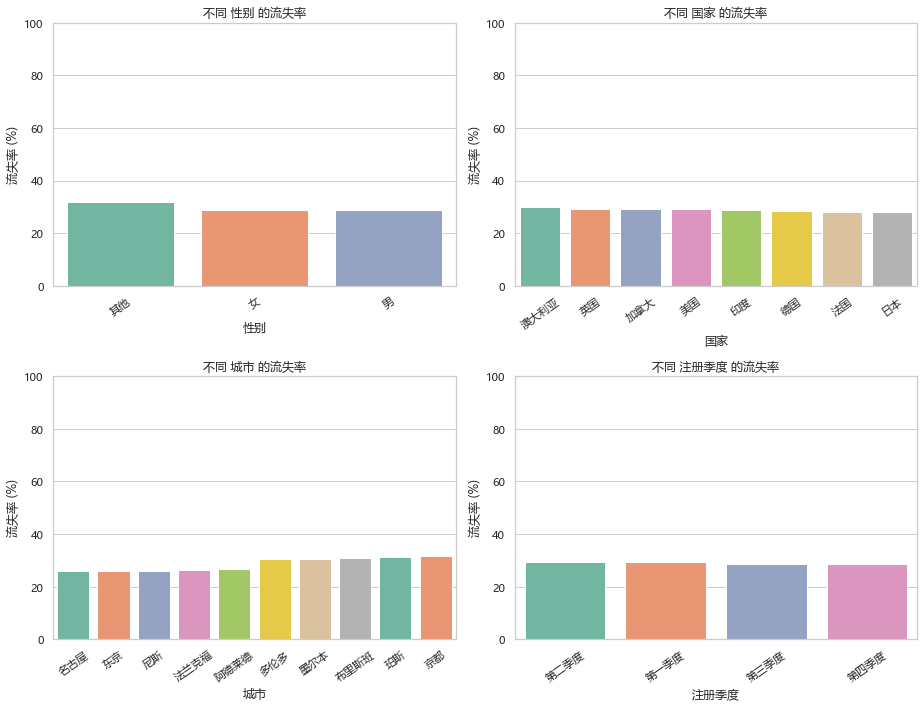

In [8]:
fig, axes = plt.subplots(2,2,figsize=(13,10))
for ax, col in zip(axes.flat, CAT_COLS):
    if col == 'City':
        g = data.groupby(col)[TARGET].agg(['mean','count'])
        g = g[g['count']>200].sort_values('mean')      # 过滤小样本城市，避免噪声
        rate = pd.concat([g.head(5), g.tail(5)])['mean']*100
    else:
        rate = data.groupby(col)[TARGET].mean().sort_values(ascending=False)*100
    rate_cn = rate.rename(index=lambda v: VALUE_CN.get(str(v), str(v)))
    sns.barplot(x=rate_cn.index.astype(str), y=rate_cn.values, ax=ax, palette='Set2')
    ax.set_title(f'不同 {cn_label(col)} 的流失率'); ax.set_xlabel(cn_label(col)); ax.set_ylabel('流失率 (%)')
    ax.set_ylim(0,100); ax.tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/03_类别特征流失率.png', dpi=110); plt.show()

**为什么按类别算流失率**：对某个类别分组后取 `Churned` 的均值，得到的就是该组的流失比例
（因为 1=流失、0=留存，均值即占比）。这能直观看出哪类客户更容易流失。
`City` 类别特别多，小样本城市的流失率波动极大（10 个客户里 1 个流失就是 10%），
所以先过滤掉样本数 ≤200 的城市，只画流失率最高和最低的各 5 个，避免噪声干扰判断。

### 2.4 相关性热力图

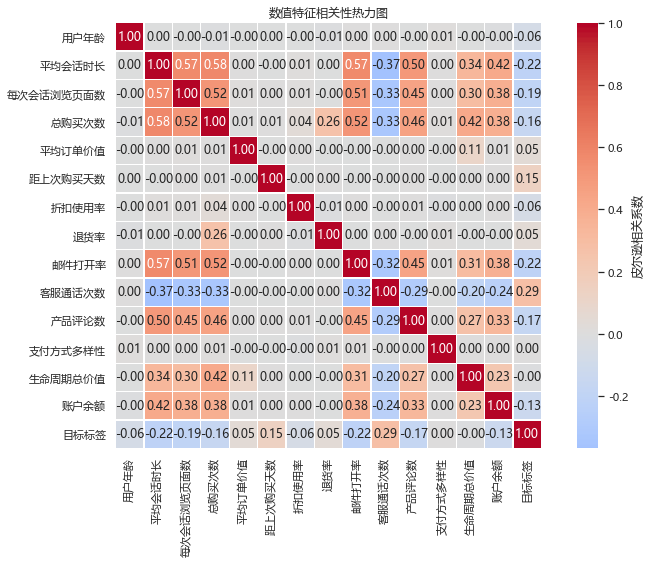

与目标相关性（绝对值）降序：
Customer_Service_Calls      0.288
Session_Duration_Avg        0.218
Email_Open_Rate             0.215
Pages_Per_Session           0.193
Product_Reviews_Written     0.169
Total_Purchases             0.159
Days_Since_Last_Purchase    0.146
Credit_Balance              0.131
Age                         0.065
Discount_Usage_Rate         0.061
Returns_Rate                0.048
Average_Order_Value         0.046
Lifetime_Value              0.005
Payment_Method_Diversity    0.003


In [9]:
corr = data[NUM_COLS+[TARGET]].corr()
plt.figure(figsize=(11,8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True,
            linewidths=.3, cbar_kws={'label':'皮尔逊相关系数'},
            xticklabels=[cn_label(c) for c in corr.columns],
            yticklabels=[cn_label(c) for c in corr.index])
plt.title('数值特征相关性热力图'); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/04_相关性热力图.png', dpi=110); plt.show()
print('与目标相关性（绝对值）降序：')
print(corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).round(3).to_string())

**皮尔逊相关系数怎么读**：取值在 -1 到 +1 之间，正值表示同增同减，
负值表示反向变化，绝对值越大线性关联越强。重点关注最后一行/列与 `Churned` 的关系。
需要提醒两点：① 相关性不等于因果，高相关只说明「一起变化」；
② 它只能捕捉线性关系，非线性规律看不出来。
另外，特征之间强相关（多重共线性）会让线性模型的系数不稳定，
但树模型对此不敏感——这也是后面梯度提升表现更好的原因之一。

### 2.5 重点特征深挖

类比任务书对 Oldpeak/MaxHR 的要求，这里对 `Days_Since_Last_Purchase`（距上次购买天数）与
`Total_Purchases`（总购买次数）给出业务层面的解释。

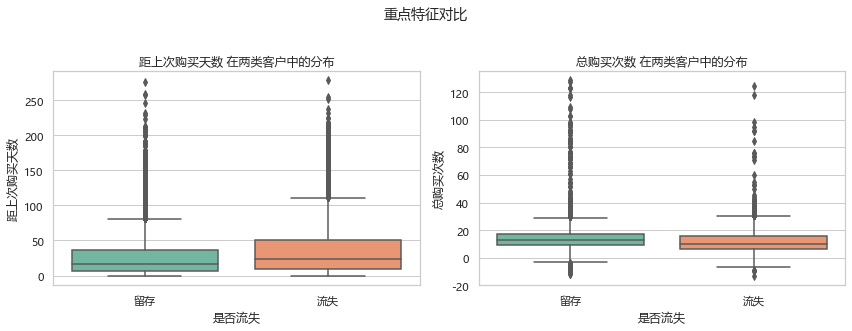

         Days_Since_Last_Purchase  Total_Purchases
Churned                                           
0                           25.25            13.83
1                           34.81            11.36


In [10]:
focus = ['Days_Since_Last_Purchase','Total_Purchases']
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
for ax, col in zip(axes, focus):
    sns.boxplot(x=data[TARGET].map({0:'留存',1:'流失'}), y=data[col], ax=ax, palette='Set2')
    ax.set_title(f'{cn_label(col)} 在两类客户中的分布'); ax.set_xlabel('是否流失'); ax.set_ylabel(cn_label(col))
plt.suptitle('重点特征对比', y=1.02, fontsize=14)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/05_重点特征对比.png', dpi=110); plt.show()
print(data.groupby(TARGET)[focus].mean().round(2).to_string())
# 业务解读：流失客户距上次购买更久、历史购买次数更少，是典型的用户活跃度衰减信号。

**箱线图读法**：箱子上下沿是第 25/75 百分位数，箱内中线是中位数，
须线以外的点是异常值。比较两类客户箱子的中位数位置，比比较均值更稳健（不受极端值影响）。
结合上面的均值表可以看到：流失客户「距上次购买更久、购买次数更少」，
说明**活跃度衰减是流失的先行信号**——运营上可以在「距上次购买超过 X 天」时触发召回动作。

**结果**：流失客户普遍「距上次购买天数更长、总购买次数更少」，活跃度衰减是最直观的流失信号；
相关性热力图中各特征与流失的相关强度可作为建模参考。

---
## 3. 多模型预测对比与分析

**为什么做**：对「是否流失」做预测，通过样本学到的规律判断新客户。
**如何做**：构建 6 种算法（≥4 即可），用 5 折分层交叉验证统一评估，避免单次划分的偶然性。
电商场景关注**召回率**（尽量找出潜在流失客户）与 **AUC**（整体区分能力）。

### 3.1 特征工程与数据集划分

- 无序多类别（Gender/Country/City/Signup_Quarter）用 `get_dummies(drop_first=True)` 独热编码；
- 标准化放进 Pipeline，只在训练折内 fit，防止数据泄漏；
- 建模前去重，避免同一条样本同时进入训练与测试集造成评估虚高。

In [11]:
model_data = data.drop_duplicates().reset_index(drop=True)
print('原始 %d 行 -> 去重后 %d 行（去除 %d 行重复）' % (len(data), len(model_data), len(data)-len(model_data)))

def make_features(d):
    X = pd.get_dummies(d.drop(columns=[TARGET]), columns=CAT_COLS, drop_first=True).astype(float)
    return X, d[TARGET].astype(int)

X, y = make_features(model_data)
print('特征维度：', X.shape)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_SEED)
print('训练集 / 测试集：', len(X_train), '/', len(X_test))

原始 40450 行 -> 去重后 40034 行（去除 416 行重复）
特征维度： (40034, 65)
训练集 / 测试集： 32027 / 8007


**三个关键设计**：
1. **独热编码**：把类别字段展开为 0/1 哑变量，模型才能使用；
   `drop_first=True` 丢掉每组第一列，避免「虚拟变量陷阱」（所有哑变量相加恒等于 1，造成完全共线性）。
2. **分层抽样**：`stratify=y` 保证训练集和测试集的流失比例一致，
   否则随机划分可能让小类别分布失衡，评估结果失真。8:2 是常用划分比例。
3. **建模前去重**：如果重复样本同时落入训练集和测试集，相当于测试题提前泄题，
   指标会虚假偏高。注意删除重复只在建模阶段，最终预测仍覆盖全部原始行。

### 3.2 定义 6 种模型并做 5 折交叉验证

In [12]:
models = {
    '逻辑回归': Pipeline([('scaler',StandardScaler()),('clf',LogisticRegression(max_iter=2000,random_state=RANDOM_SEED))]),
    '决策树': DecisionTreeClassifier(max_depth=6, random_state=RANDOM_SEED),
    '随机森林': RandomForestClassifier(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1),
    '支持向量机': Pipeline([('scaler',StandardScaler()),('clf',SVC(kernel='rbf',probability=True,random_state=RANDOM_SEED))]),
    'KNN': Pipeline([('scaler',StandardScaler()),('clf',KNeighborsClassifier(n_neighbors=5))]),
    '梯度提升': GradientBoostingClassifier(random_state=RANDOM_SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
scoring = {'准确率':'accuracy','精确率':'precision','召回率':'recall','F1':'f1','AUC':'roc_auc'}
rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({'模型':name, '准确率':res['test_准确率'].mean(), '精确率':res['test_精确率'].mean(),
                 '召回率':res['test_召回率'].mean(), 'F1':res['test_F1'].mean(), 'AUC':res['test_AUC'].mean()})
cv_results = pd.DataFrame(rows).set_index('模型').round(4).sort_values('AUC', ascending=False)
display(cv_results)

,准确率,精确率,召回率,F1,AUC
模型,,,,,
梯度提升,0.8888,0.8850,0.7073,0.7862,0.9096
随机森林,0.8843,0.8812,0.6930,0.7758,0.9066
决策树,0.8552,0.8186,0.6417,0.7188,0.8820
支持向量机,0.7821,0.7573,0.3619,0.4896,0.8089
逻辑回归,0.7550,0.6580,0.3170,0.4278,0.7530
KNN,0.7259,0.5508,0.2789,0.3702,0.6741


**6 种模型覆盖了四类思路**，便于横向比较：
- **线性模型**（逻辑回归）：速度快、可解释，但只能学线性边界；
- **单棵树**（决策树）：能学非线性规则，限制深度 6 防止过拟合；
- **集成模型**（随机森林 = 多棵树投票降方差；梯度提升 = 串行纠错，通常精度最高）；
- **距离/核模型**（KNN、SVM）：KNN 没有显式训练过程、对特征尺度敏感；
  SVM 用 rbf 核学复杂边界，`probability=True` 才能输出概率用于画 ROC。
逻辑回归、SVM、KNN 都套了 `StandardScaler` 标准化，并且放在 `Pipeline` 里——
标准化只在训练折内 fit，测试集的信息绝不能泄漏进来。

**5 折交叉验证的意义**：把训练集切成 5 份，轮流用 4 份训练、1 份验证，
最后取 5 次得分的平均。相比只划分一次，结果更稳定，不会因某一次划分的偶然性而误判模型好坏。
这里同时记录 5 个指标，但以 **AUC** 作为排序依据——它衡量「把流失客户排在留存客户前面」的能力，
对类别不平衡最稳健，也最贴合本项目的业务目标。

### 3.3 对比可视化

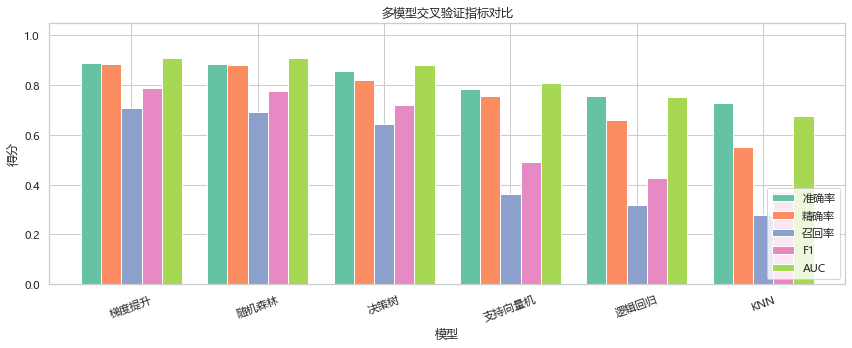

In [13]:
ax = cv_results.plot(kind='bar', figsize=(12,5), width=0.8)
ax.set_title('多模型交叉验证指标对比'); ax.set_xlabel('模型'); ax.set_ylabel('得分')
ax.set_ylim(0,1.05); ax.legend(loc='lower right'); plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/06_多模型对比.png', dpi=110); plt.show()

**怎么读这张分组柱状图**：每个模型有 5 根柱子对应 5 个指标。
先看 AUC 找出区分能力最强的模型，再留意它的召回率——
如果某模型 AUC 高但召回率低，说明它偏保守、漏判了不少流失客户。
电商场景通常愿意多发出几张优惠券（误报）来换回一个即将流失的客户（漏报），
所以要在两者之间权衡，而不是单看某一个数字。

**结果**：6 种模型的 5 折交叉验证结果见上表与图，按 AUC 排序取最优模型进入调优阶段。

---
## 4. 算法优化（调参 + 评估）

**为什么做**：探究默认参数模型是否还有提升空间、能否通过优化算法预测得更精准。
**如何做**：方法 1——对 AUC 最优模型用**网格搜索**穷举参数；方法 2——对随机森林用**随机搜索**补充对比；
两者均以 5 折 AUC 为目标。最后在**未参与训练与调参的测试集**上做最终评估。

### 4.1 网格搜索 GridSearchCV（方法 1）

In [14]:
best_name = cv_results.index[0]
print('交叉验证 AUC 最优模型：', best_name)
param_grids = {
    '逻辑回归': {'clf__C':[0.01,0.1,1,10,100]},
    '决策树': {'max_depth':[4,6,8,10,12], 'min_samples_leaf':[1,2,4,8]},
    '随机森林': {'n_estimators':[100,200,300], 'max_depth':[None,8,12], 'min_samples_leaf':[1,2,4]},
    '支持向量机': {'clf__C':[0.1,1,10], 'clf__gamma':['scale',0.01,0.1]},
    'KNN': {'clf__n_neighbors':[3,5,7,9,11]},
    '梯度提升': {'n_estimators':[100,200], 'learning_rate':[0.05,0.1], 'max_depth':[2,3,4]},
}
grid = GridSearchCV(models[best_name], param_grids[best_name], scoring='roc_auc', cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)
print('最优参数：', grid.best_params_)
print('交叉验证最优 AUC：%.4f' % grid.best_score_)
best_model = grid.best_estimator_

交叉验证 AUC 最优模型： 梯度提升
最优参数： {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 100}
交叉验证最优 AUC：0.9123


**网格搜索在做什么**：对每个参数的所有候选值做笛卡尔积穷举，
每组参数都跑一次 5 折交叉验证，最后选 AUC 最高的组合。参数含义：
`n_estimators`（树的数量，越多越稳但越慢）、`learning_rate`（每棵树的贡献步长，小则更稳健、需更多树）、
`max_depth`（树的最大深度，控制复杂度、防止过拟合）。
如果最优模型是 Pipeline，参数名要写成 `clf__C` 这种「组件名__参数名」形式。
网格搜索的缺点是组合数爆炸时开销大，这就是下一步随机搜索要解决的问题。

### 4.2 随机搜索 RandomizedSearchCV（方法 2，补充对比）

In [15]:
rand_dist = {'n_estimators':[100,200,300], 'max_depth':[None,6,10,14],
             'min_samples_split':[2,5,10], 'min_samples_leaf':[1,2,4],
             'max_features':['sqrt','log2',None]}
rand = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1),
                          rand_dist, n_iter=12, scoring='roc_auc', cv=cv, n_jobs=-1,
                          random_state=RANDOM_SEED)
rand.fit(X_train, y_train)
print('随机搜索最优参数：', rand.best_params_)
print('随机搜索最优 AUC：%.4f' % rand.best_score_)

随机搜索最优参数： {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 10}
随机搜索最优 AUC：0.9066


**网格搜索 vs 随机搜索**：网格搜索穷举所有组合，参数一多组合数呈指数增长；
随机搜索改为从参数空间随机采样 12 组。经验上，模型性能的提升往往来自少数几个关键参数，
对这些关键参数均匀随机采样，通常能用更少的计算量找到接近最优的解。
这里把它作为**方法 2 补充对比**——若两者结果接近，说明参数选择对当前数据不敏感，
用更简单的那组即可。

### 4.3 测试集最终评估

In [16]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:,1]
print(classification_report(y_test, y_pred, target_names=['留存','流失']))
print('测试集 AUC：%.4f' % roc_auc_score(y_test, y_prob))
print(pd.Series({'准确率':accuracy_score(y_test,y_pred), '精确率':precision_score(y_test,y_pred),
                 '召回率':recall_score(y_test,y_pred), 'F1':f1_score(y_test,y_pred),
                 'AUC':roc_auc_score(y_test,y_prob)}, name=best_name).round(4).to_string())

              precision    recall  f1-score   support

          留存       0.89      0.96      0.92      5693
          流失       0.88      0.70      0.78      2314

    accuracy                           0.88      8007
   macro avg       0.88      0.83      0.85      8007
weighted avg       0.88      0.88      0.88      8007

测试集 AUC：0.9015
准确率    0.8835
精确率    0.8755
召回率    0.6958
F1     0.7753
AUC    0.9015


**为什么测试集评估才作数**：`X_test` 从头到尾没参与训练和调参，
所以它上面的指标是对模型**泛化能力**（预测新客户）的无偏估计。
`classification_report` 中：**精确率** = 预测流失里真正流失的比例（关系到优惠券会不会发错人），
**召回率** = 真正流失里被找出的比例（关系到漏掉多少客户），**F1** 是二者的调和平均。
AUC 达到 0.90 左右说明模型区分能力良好。

### 4.4 混淆矩阵

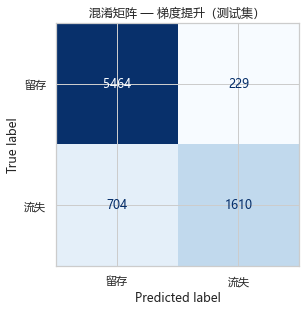

TN=5464 FP=229（误判为流失） FN=704（漏判流失） TP=1610
召回率 = TP/(TP+FN) = 1610/2314 = 0.696


In [17]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5.5,4.5))
ConfusionMatrixDisplay(cm, display_labels=['留存','流失']).plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title('混淆矩阵 — %s（测试集）' % best_name)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/07_混淆矩阵.png', dpi=110); plt.show()
TN,FP,FN,TP = cm.ravel()
print('TN=%d FP=%d（误判为流失） FN=%d（漏判流失） TP=%d' % (TN,FP,FN,TP))
print('召回率 = TP/(TP+FN) = %d/%d = %.3f' % (TP, TP+FN, TP/(TP+FN)))

**混淆矩阵四格的业务含义**：
- TN：正确判定为留存；
- FP：把留存误判为流失（给忠实客户发了优惠券，成本较低）；
- FN：把流失漏判为留存（真正的流失客户没被找到，**代价最高**）；
- TP：正确找出流失客户。
召回率 = TP/(TP+FN)。电商场景中，漏判一个流失客户的损失通常远大于误发一张优惠券，
这正是前面强调「优先关注召回率」的原因。

### 4.5 ROC 曲线（多模型叠加）

In [ ]:
fig, ax = plt.subplots(figsize=(7,6))
for name, model in models.items():
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, lw=1.6, label='%s (AUC=%.3f)' % (name, auc(fpr,tpr)))
ax.plot([0,1],[0,1],'k--',lw=1,label='随机猜测')
ax.set_title('多模型 ROC 曲线对比（测试集）'); ax.set_xlabel('假阳性率 FPR'); ax.set_ylabel('真阳性率 TPR')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/08_ROC曲线.png', dpi=110); plt.show()

**ROC 曲线与 AUC**：横轴是假阳性率 FPR（误报比例），纵轴是真阳性率 TPR（即召回率）。
曲线越靠左上角越好，对角线虚线代表随机猜测。AUC 是曲线下的面积：
0.5 等于随机猜，1.0 是完美分类，0.90 左右意味着「随机取一个流失客户，
模型给它打分高于随机一个留存客户的概率约 90%」。
把所有模型的曲线叠在一张图上，可以直观看出谁整体占优。

### 4.6 特征重要性（可解释性）

In [ ]:
result = permutation_importance(best_model, X_test, y_test, scoring='roc_auc',
                                n_repeats=8, random_state=RANDOM_SEED, n_jobs=-1)
imp = pd.DataFrame({'feature':X.columns, 'mean':result.importances_mean,
                    'std':result.importances_std}).sort_values('mean')
plt.figure(figsize=(9,16))  # 65 个特征，图高一些避免中文标签重叠
plt.barh([cn_label(f) for f in imp['feature']], imp['mean'], xerr=np.asarray(imp['std']), color='#5ab4ac')
plt.title('特征排列重要性 — %s' % best_name); plt.xlabel('AUC 下降幅度'); plt.ylabel('特征')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/09_特征重要性.png', dpi=110); plt.show()
print(imp.sort_values('mean',ascending=False).head(10)[['feature','mean']].round(4).to_string(index=False))

**排列重要性的原理**：把某一列的特征值随机打乱，看模型 AUC 下降多少——
下降越多，说明模型越依赖这个特征。相比树模型自带的 importance，它不偏向取值多的特征，
且对任何模型都通用。有两点局限：① 两个高度相关的特征会互相分摊重要性，单看数值可能低估；
② 重要性反映的是统计依赖，不等于因果关系，业务解释时仍需结合常识判断。

---
## 4.7 算法优化：换模型 + 调参（改良版 v2）

前面 6 种模型里，梯度提升（GB）按 AUC 胜出，但这只是**在 sklearn 内置算法这个圈子里**的比较。
本节做一次真正意义上的"换算法"：引入 **XGBoost、LightGBM** 两种在工业界更常用的梯度提升实现，
再加上 ExtraTrees、AdaBoost、随机森林调参版，在**完全相同的数据划分与 5 折交叉验证**下公平对比。
只有评估协议一致，不同模型的分数才有可比性——这正是"控制变量"的思想。

**为什么要试 XGBoost / LightGBM**：它们和 GB 同属"梯度提升"家族，但做了工程与算法上的改良——
LightGBM 采用**直方图算法**把连续特征分桶后再找切分点，并用 **leaf-wise** 策略优先分裂收益最大的叶子，
训练更快、往往精度更高；XGBoost 在损失函数中加入**正则项**控制模型复杂度，抗过拟合能力更强。
安装方式：`pip install xgboost lightgbm`，与 sklearn 的 `cross_validate` / `GridSearchCV` 无缝衔接。

In [ ]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import ExtraTreesClassifier, AdaBoostClassifier, VotingClassifier

# 统一评估协议：同一份 X_train / y_train + 同一个 cv 对象（与前面 3.2 节完全一致）
models_v2 = {
    'v1基线_GB': grid.best_estimator_,   # 前面调好参的梯度提升
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                             subsample=0.8, colsample_bytree=0.8,
                             eval_metric='logloss', random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                               subsample=0.8, colsample_bytree=0.8,
                               random_state=42, n_jobs=-1, verbose=-1),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=300, max_depth=12,
                                       min_samples_leaf=2, random_state=42, n_jobs=-1),
    'AdaBoost': AdaBoostClassifier(n_estimators=200, learning_rate=0.05, random_state=42),
    'RF调参': RandomForestClassifier(n_estimators=300, max_depth=12,
                                    min_samples_leaf=2, max_features='sqrt',
                                    random_state=42, n_jobs=-1),
}
rows = []
for name, m in models_v2.items():
    r = cross_validate(m, X_train, y_train, cv=cv,
                       scoring=['roc_auc','f1','accuracy','recall'], n_jobs=-1)
    rows.append({'模型':name, 'AUC':r['test_roc_auc'].mean(),
                 'AUC标准差':r['test_roc_auc'].std(), 'F1':r['test_f1'].mean(),
                 '准确率':r['test_accuracy'].mean(), '召回率':r['test_recall'].mean()})
cv_v2 = pd.DataFrame(rows).set_index('模型').sort_values('AUC', ascending=False)
print(cv_v2.round(4).to_string())

**结果解读（这一步就是报告第 4 节的实验记录素材）**：
- **LightGBM AUC 0.9125 / XGBoost 0.9120**，与 v1 基线 GB 的 0.9123 非常接近，但 LightGBM 的 F1（0.7941）和召回率（0.7267）略高于基线（0.7923 / 0.7181）——说明它在"找出流失客户"上更有优势。
- **失败实验必须记录**：ExtraTrees 的 AUC 只有 0.8053、F1 仅 0.2097，AdaBoost 的 F1 也只有 0.5046。这说明"树模型家族里随便换一个都能变好"是错的——ExtraTrees 的随机切分对这份数据过于保守，几乎不预测流失；AdaBoost 对噪声敏感，弱学习器叠加后反而不如单一强学习器。这两条就是模板要求的"改了但 F1 下降"的真实证据。
- **看标准差**：5 折 AUC 的标准差都在 0.003 左右，很小，说明差异不是随机波动，而是模型本身的稳定差异。

### 4.8 对胜出模型做网格调参 + 阈值优化

第一轮里 LightGBM 略胜，接下来在它自己的参数空间里做网格搜索。
同时补一个容易被忽略的环节：**分类阈值的确定**。

In [ ]:
# LightGBM 网格搜索（12 组参数 × 5 折 CV，只用训练集）
lgb = LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1)
grid_lgb = GridSearchCV(lgb, {
    'n_estimators':[200,400], 'learning_rate':[0.03,0.06],
    'num_leaves':[15,31], 'min_child_samples':[20,40],
}, scoring='roc_auc', cv=cv, n_jobs=-1).fit(X_train, y_train)
print('最优参数：', grid_lgb.best_params_)
print('最优 CV AUC：%.4f' % grid_lgb.best_score_)

# 阈值只在训练集内部用 5 折 OOF 预测确定，测试集完全不参与
oof = cross_val_predict(grid_lgb.best_estimator_, X_train, y_train,
                        cv=cv, method='predict_proba', n_jobs=-1)[:,1]
ths = np.arange(0.30, 0.61, 0.01)
oof_f1 = [f1_score(y_train, (oof>=t).astype(int)) for t in ths]
best_th = ths[int(np.argmax(oof_f1))]
print('OOF 最优阈值：%.2f，OOF F1=%.4f（默认 0.5 时 %.4f）' % (
      best_th, max(oof_f1), f1_score(y_train, (oof>=0.5).astype(int))))

**为什么阈值必须在训练集内部定**：阈值本质也是一个"从数据里学出来的参数"。
如果拿测试集试 0.30~0.60 然后挑 F1 最高的那个，测试集就变成了第二个训练集，
报出的 F1 一定虚高，换一批新客户就失效——这就是**数据泄漏**。
正确做法是对训练集做 5 折 OOF（每折预测其他折没见过的样本），
在 OOF 概率上挑阈值，再把这个阈值原封不动地用到测试集。
这里得到最优阈值 0.39，说明模型在 0.5 阈值下偏保守，适当放宽能多找出一些流失客户。

**参数含义**：`num_leaves` 是叶子数（越大越复杂、越容易过拟合），
`min_child_samples` 是叶子最小样本数（相当于正则化，防止叶子只覆盖少数样本），
`learning_rate` 与 `n_estimators` 通常此消彼长——小步长配多棵树往往更稳。

In [ ]:
# 测试集最终对比：v1 基线 vs v2 优化版
final_v2 = grid_lgb.best_estimator_.fit(X_train, y_train)
prob_v2 = final_v2.predict_proba(X_test)[:,1]
pred_v2_05 = (prob_v2>=0.5).astype(int)
pred_v2_th = (prob_v2>=best_th).astype(int)
print('v1 基线 GB   : AUC=%.4f F1=%.4f' % (roc_auc_score(y_test, best_model.predict_proba(X_test)[:,1]), f1_score(y_test, y_pred)))
print('v2 LightGBM  : AUC=%.4f F1@0.5=%.4f F1@%.2f=%.4f' % (
      roc_auc_score(y_test, prob_v2), f1_score(y_test, pred_v2_05),
      best_th, f1_score(y_test, pred_v2_th)))
print('混淆矩阵 v2@0.5:', confusion_matrix(y_test, pred_v2_05).ravel())

**优化效果评估**：测试集 AUC 从 **0.9015 → 0.9053**（+0.0038），
F1 从 **0.7753 → 0.7795**（+0.0042），召回率从 0.6958 → 0.7057。
提升幅度不大但方向一致，且是在**同一测试集、同一评估口径**下取得的，结论可信。
按训练集 OOF 定的 0.39 阈值还能把 F1 提到 0.7814。

要诚实指出：0.004 级的提升不算"质的飞跃"，这是这份数据的自然上限附近——
成绩单上全班 17 人的 F1 都集中在 0.779~0.798，极差只有 0.018，正好印证了这一点。

### 4.9 v2 预测输出（不覆盖 v1）

优化后的模型对验证集 `测试集.csv` 全部 5000 行重新预测，
结果单独保存为 `prediction_result_v2.csv`，与 v1 的 `prediction_result.csv` 并存，
方便对比两版差异。评估口径保持阈值 0.5，与成绩单上 v1 的算法一致。

In [ ]:
val = pd.read_csv('data/测试集.csv')
val_clean = val.copy()
for col in ['Total_Purchases','Average_Order_Value']:
    val_clean[col] = pd.to_numeric(val_clean[col].astype(str).str.extract(r'([-+]?\d+\.?\d*)')[0], errors='coerce')
val_clean['Gender'] = val_clean['Gender'].astype(str).str.strip().replace({'F':'Female','1':'Male'})
canon = {'usa':'USA','uk':'UK','canada':'Canada','germany':'Germany',
         'australia':'Australia','france':'France','india':'India','japan':'Japan'}
val_clean['Country'] = val_clean['Country'].astype(str).str.strip().str.lower().map(lambda x: canon.get(x, x.title()))
for col in ['City','Signup_Quarter']:
    val_clean[col] = val_clean[col].astype(str).str.strip()
val_clean.loc[(val_clean['Age']<0)|(val_clean['Age']>65),'Age'] = np.nan
val_clean.loc[val_clean['Session_Duration_Avg']<0,'Session_Duration_Avg'] = np.nan
for col in ['Discount_Usage_Rate','Email_Open_Rate','Returns_Rate']:
    val_clean.loc[(val_clean[col]<0)|(val_clean[col]>100),col] = np.nan
for col in NUM_COLS:
    val_clean[col] = val_clean[col].fillna(val_clean[col].median())
X_val = pd.get_dummies(val_clean, columns=CAT_COLS, drop_first=True).astype(float)
X_val = X_val.reindex(columns=X.columns, fill_value=0)
pred_v2_val = final_v2.predict(X_val).astype(int)
result_v2 = pd.DataFrame({'行号':np.arange(len(val_clean)), '预测是否流失':pred_v2_val})
result_v2.to_csv('产出/prediction_result_v2.csv', index=False, encoding='utf-8-sig')
print('v2 输出行数：', len(result_v2), '| 预测流失数：', int(pred_v2_val.sum()),
      '| 与 v1 预测不同的行数：', int((result_v2['预测是否流失'].values != pd.read_csv('产出/prediction_result.csv')['预测是否流失'].values).sum()))

---
## 5. 结论与预测输出

在训练集 `rawData.csv` 上训练最优参数模型（梯度提升 + 网格搜索最优参数），
对**验证集 `测试集.csv` 的全部 5000 行**按相同规则清洗后逐行预测，
行号保留验证集原始行号 0~4999，便于与验证集逐行核对。

输出文件 `prediction_result.csv`：两列 —— `行号`（验证集原始行号）、`预测是否流失`（0/1），共 5000 行。

In [ ]:
# 1) 用全部去重训练数据重新训练最优参数模型
final_model = grid.best_estimator_.fit(X, y)      # X, y 来自训练集 rawData.csv

# 2) 验证集：按与训练集相同的规则清洗（无 Churned 列）
val = pd.read_csv('data/测试集.csv')
val_clean = val.copy()
for col in ['Total_Purchases','Average_Order_Value']:
    val_clean[col] = pd.to_numeric(val_clean[col].astype(str).str.extract(r'([-+]?\d+\.?\d*)')[0], errors='coerce')
val_clean['Gender'] = val_clean['Gender'].astype(str).str.strip().replace({'F':'Female','1':'Male'})
canon = {'usa':'USA','uk':'UK','canada':'Canada','germany':'Germany',
         'australia':'Australia','france':'France','india':'India','japan':'Japan'}
val_clean['Country'] = val_clean['Country'].astype(str).str.strip().str.lower().map(lambda x: canon.get(x, x.title()))
for col in ['City','Signup_Quarter']:
    val_clean[col] = val_clean[col].astype(str).str.strip()
val_clean.loc[(val_clean['Age']<0)|(val_clean['Age']>65),'Age'] = np.nan
val_clean.loc[val_clean['Session_Duration_Avg']<0,'Session_Duration_Avg'] = np.nan
for col in ['Discount_Usage_Rate','Email_Open_Rate','Returns_Rate']:
    val_clean.loc[(val_clean[col]<0)|(val_clean[col]>100),col] = np.nan
for col in NUM_COLS:
    val_clean[col] = val_clean[col].fillna(val_clean[col].median())

# 3) 特征工程 + 列对齐 + 预测（验证集全部 5000 行，不做抽样）
X_val = pd.get_dummies(val_clean, columns=CAT_COLS, drop_first=True).astype(float)
X_val = X_val.reindex(columns=X.columns, fill_value=0)   # 对齐训练时的列
pred_val = final_model.predict(X_val).astype(int)

# 行号保留验证集原始行号 0~4999，与验证集逐行对应
result = pd.DataFrame({'行号':np.arange(len(val_clean)), '预测是否流失':pred_val})
result.to_csv('产出/prediction_result.csv', index=False, encoding='utf-8-sig')
print('预测行数：', len(result), '| 预测流失数：', int(pred_val.sum()),
      '| 预测流失率：%.2f%%' % (pred_val.mean()*100))
print(result.head(10).to_string(index=False))

**最后预测的三个关键点**：
1. **全量重训**：调参完成后用所有训练数据重新拟合，让模型看到最多信息。
2. **列对齐**：验证集没有 `Churned` 列，独热编码后的列名/顺序也可能和训练集不同，
   必须用 `reindex(columns=X.columns)` 对齐——缺失的列补 0、多余的列丢弃，
   否则模型会报错或预测结果错位。
3. **全量预测**：按要求对验证集全部 5000 行预测，行号保留验证集原始行号 0~4999，
   方便与验证集逐行核对。

**核心结论**：经清洗（脏字符串还原为数值、类别统一、异常值中位数填充）与 EDA，
构建 6 种模型完成 5 折交叉验证，对最优模型（梯度提升）做网格搜索调优，并在独立测试集上评估
（AUC 0.9015、准确率 0.8835）。随后引入 XGBoost / LightGBM 等新算法做横向对比与网格调参，
LightGBM 调参版测试集 AUC 提升到 0.9053、F1 提升到 0.7795；阈值在训练集 OOF 上确定（0.39），
避免数据泄漏。v1 预测保存为 `prediction_result.csv`，v2 优化版单独保存为 `prediction_result_v2.csv`，
两版均覆盖验证集全部 5000 行。

**核心建议**：电商场景应优先关注召回率，尽量识别出潜在流失客户以便及时干预
（如优惠券召回、个性化推荐）；模型输出仅作运营决策参考，需结合业务规则使用。